# 02 · Every bus segment in the city, and do bus lanes help?

This notebook measures how long buses take between every pair of consecutive stops, compares rush hour with late night,
and tests whether segments with a bus lane hold their speed better than segments without one.

It saves its tables to `data/analysis.duckdb`, which notebook 03 builds on.

In [11]:
import os, sys
from pathlib import Path
import duckdb

# find the project folder (the one containing scripts/) from wherever this notebook runs
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "corridors.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "scripts"))

con = duckdb.connect("data/analysis.duckdb")   # saved to disk so notebook 03 can use these tables

## Can the feed tell us when buses reach each stop?

Every ping says which stop the bus is heading to (`stop_sequence`) and whether it's stopped there
(`current_status` 1) or moving toward it (2). If those are filled in, stop-to-stop timing comes straight from the feed.

In [12]:
con.sql("""
    SELECT current_status,
           count(*) AS pings,
           round(100.0 * count(*) / sum(count(*)) OVER (), 1) AS pct,
           round(100.0 * count(stop_sequence) / count(*), 1) AS pct_with_stop_seq
    FROM 'data/bus_positions.parquet'
    GROUP BY current_status
    ORDER BY current_status
""").show()

┌────────────────┬─────────┬────────┬───────────────────┐
│ current_status │  pings  │  pct   │ pct_with_stop_seq │
│     int64      │  int64  │ double │      double       │
├────────────────┼─────────┼────────┼───────────────────┤
│              1 │ 6002241 │   55.6 │             100.0 │
│              2 │ 4783543 │   44.4 │             100.0 │
└────────────────┴─────────┴────────┴───────────────────┘



Every ping has a stop sequence, so the approach works.

## Build the stop-to-stop segments

1. `stop_events`: one row per trip per stop, with the first moment the bus headed for that stop and the first moment it was stopped there.
2. `segments`: line those up in order (window functions `lag` / `lead`) and subtract, giving the running time for each hop.
   Time spent boarding at a stop is left out, and so are each trip's first and last hops, where buses lay over.
   The `4 HOUR` shift makes trips that run past midnight count toward the day they started.

In [13]:
con.sql("""
CREATE OR REPLACE TABLE stop_events AS
SELECT route_id, direction_id, trip_id, vehicle_id,
       (ts_local - INTERVAL 4 HOUR)::DATE AS service_date,
       stop_sequence,
       any_value(stop_id) AS stop_id,
       min(vehicle_ts) FILTER (WHERE current_status = 2) AS first_transit,
       min(vehicle_ts) FILTER (WHERE current_status = 1) AS first_stopped
FROM 'data/bus_positions.parquet'
WHERE trip_id IS NOT NULL
GROUP BY route_id, direction_id, trip_id, vehicle_id, service_date, stop_sequence
""")

con.sql("""
CREATE OR REPLACE TABLE segments AS
WITH e AS (
    SELECT *,
           lag(stop_id) OVER w AS from_stop_id,
           lead(first_transit) OVER w AS next_transit,
           row_number() OVER w AS n,
           count(*) OVER (PARTITION BY trip_id, vehicle_id, service_date) AS n_stops
    FROM stop_events
    WINDOW w AS (PARTITION BY trip_id, vehicle_id, service_date ORDER BY stop_sequence)
)
SELECT route_id, direction_id, trip_id, vehicle_id, service_date,
       from_stop_id, stop_id AS to_stop_id,
       timezone('America/New_York', to_timestamp(first_transit)) AS depart_local,
       least(coalesce(first_stopped, next_transit), coalesce(next_transit, first_stopped))
           - first_transit AS run_secs
FROM e
WHERE n BETWEEN 3 AND n_stops - 1
  AND first_transit IS NOT NULL
""")

con.sql("""
    SELECT count(*) AS segment_trips,
           count(DISTINCT (from_stop_id, to_stop_id)) AS unique_segments,
           count(DISTINCT route_id) AS routes,
           round(median(run_secs)) AS median_secs,
           round(100.0 * count(*) FILTER (WHERE run_secs <= 0 OR run_secs > 900) / count(*), 2) AS pct_weird
    FROM segments
""").show()

┌───────────────┬─────────────────┬────────┬─────────────┬───────────┐
│ segment_trips │ unique_segments │ routes │ median_secs │ pct_weird │
│     int64     │      int64      │ int64  │   double    │  double   │
├───────────────┼─────────────────┼────────┼─────────────┼───────────┤
│       1466848 │           11530 │    138 │        25.0 │       0.1 │
└───────────────┴─────────────────┴────────┴─────────────┴───────────┘



About 1.47 million hops across 11,530 segments and all 138 regular bus routes, with only 0.1% unusable values.

## Night vs rush hour, per segment

For each segment: average weekday running time late at night (8 to 11pm, close to free-flow traffic),
in the morning rush (7 to 10am) and in the evening rush (4 to 7pm). The difference is the delay traffic adds.

In [14]:
con.sql("""
CREATE OR REPLACE TABLE seg_stats AS
WITH s AS (
    SELECT from_stop_id, to_stop_id, route_id, run_secs,
           CASE WHEN hour(depart_local) BETWEEN 7 AND 9   THEN 'am'
                WHEN hour(depart_local) BETWEEN 16 AND 18 THEN 'pm'
                WHEN hour(depart_local) BETWEEN 20 AND 22 THEN 'night' END AS period
    FROM segments
    WHERE dayofweek(depart_local) BETWEEN 1 AND 5
      AND run_secs > 0 AND run_secs <= 900
)
SELECT from_stop_id, to_stop_id,
       string_agg(DISTINCT route_id, ', ') AS routes,
       avg(run_secs) FILTER (WHERE period = 'night') AS night_secs,
       avg(run_secs) FILTER (WHERE period = 'am')    AS am_secs,
       avg(run_secs) FILTER (WHERE period = 'pm')    AS pm_secs,
       count(*) FILTER (WHERE period = 'night') AS night_n,
       count(*) FILTER (WHERE period = 'am')    AS am_n,
       count(*) FILTER (WHERE period = 'pm')    AS pm_n
FROM s
WHERE period IS NOT NULL
GROUP BY from_stop_id, to_stop_id
""")

CountBIGINT
9388


## Where buses lose the most time

Ranking by delay *per bus* puts quiet segments (shopping mall driveways with 15 buses) on top, so this ranks by
bus-minutes lost per weekday: delay per bus × buses per evening rush. Segments need at least 25 rush-hour buses.
(Notebook 03 goes one step further and weights by riders.)

In [15]:
con.sql("""
SELECT f.stop_name AS from_stop, t.stop_name AS to_stop, s.routes,
       round(pm_secs - night_secs) AS delay_per_bus,
       round(pm_n / 5.0) AS pm_buses_per_day,
       round((pm_secs - night_secs) * pm_n / 5.0 / 60) AS bus_minutes_lost_per_day
FROM seg_stats s
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) f ON f.stop_id = s.from_stop_id
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) t ON t.stop_id = s.to_stop_id
WHERE night_n >= 15 AND pm_n >= 25
ORDER BY bus_minutes_lost_per_day DESC
LIMIT 20
""").show(max_rows=25)

┌──────────────────────────────────┬───────────────────────────────────────┬─────────────────────────────────────┬───────────────┬──────────────────┬──────────────────────────┐
│            from_stop             │                to_stop                │               routes                │ delay_per_bus │ pm_buses_per_day │ bus_minutes_lost_per_day │
│             varchar              │                varchar                │               varchar               │    double     │      double      │          double          │
├──────────────────────────────────┼───────────────────────────────────────┼─────────────────────────────────────┼───────────────┼──────────────────┼──────────────────────────┤
│ Meridian St @ Falcon St          │ Pearl St @ Marginal St                │ 116, 114                            │         177.0 │             24.0 │                     72.0 │
│ Nubian                           │ Warren St @ Dabney Pl                 │ 28, 44, 19, 23, 14                  │ 

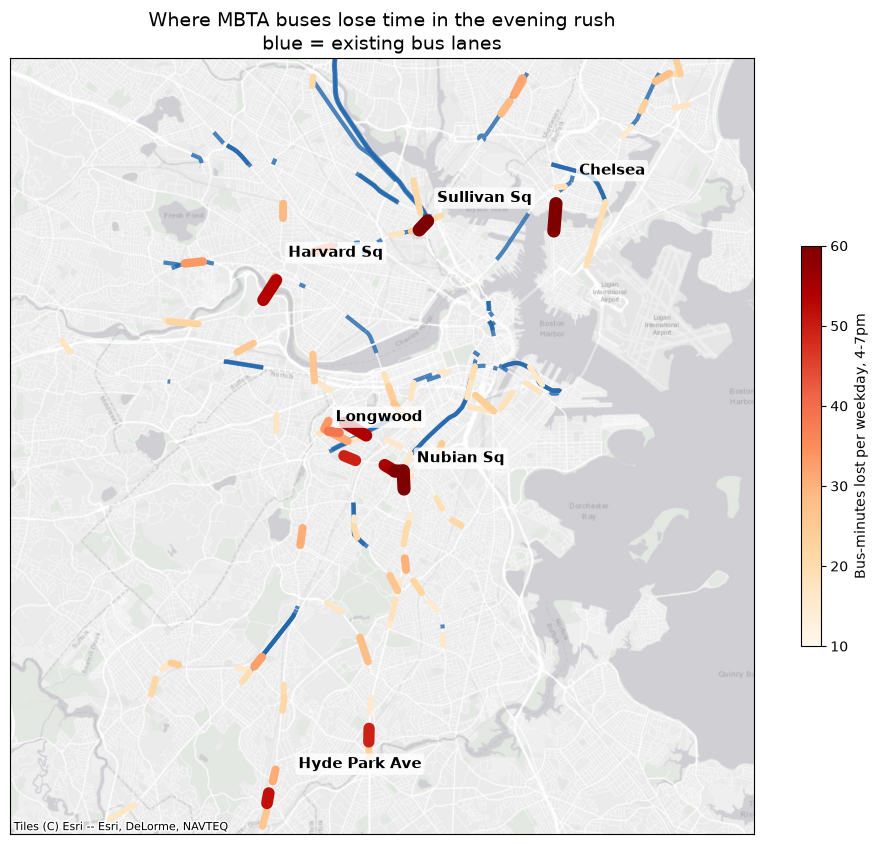

In [16]:
import json
import matplotlib.pyplot as plt
import contextily as cx
from matplotlib.collections import LineCollection

seg = con.sql("""
SELECT try_cast(f.stop_lon AS DOUBLE) AS lon1, try_cast(f.stop_lat AS DOUBLE) AS lat1,
       try_cast(t.stop_lon AS DOUBLE) AS lon2, try_cast(t.stop_lat AS DOUBLE) AS lat2,
       greatest((pm_secs - night_secs) * pm_n / 5.0 / 60, 0) AS lost
FROM seg_stats s
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) f ON f.stop_id = s.from_stop_id
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) t ON t.stop_id = s.to_stop_id
WHERE night_n >= 15 AND pm_n >= 25
""").df().dropna()
seg = seg[((seg.lon2 - seg.lon1).abs() < 0.02) & ((seg.lat2 - seg.lat1).abs() < 0.015)]   # drop long express hops

with open("data/mbta_bus_lanes.geojson") as f:
    lanes_gj = json.load(f)
lane_lines = []
for feat in lanes_gj["features"]:
    g = feat["geometry"]
    lane_lines += [g["coordinates"]] if g["type"] == "LineString" else g["coordinates"]

fig, ax = plt.subplots(figsize=(12, 13))
ax.set_xlim(-71.20, -70.98)
ax.set_ylim(42.25, 42.42)
cx.add_basemap(ax, crs="EPSG:4326", source=cx.providers.Esri.WorldGrayCanvas, zoom=13)
ax.add_collection(LineCollection(lane_lines, colors="#2166ac", linewidths=3, alpha=0.8))

top = seg[seg.lost >= 15].sort_values("lost")
lc = LineCollection([[(r.lon1, r.lat1), (r.lon2, r.lat2)] for r in top.itertuples()],
                    array=top.lost.clip(upper=60), cmap="OrRd", norm=plt.Normalize(10, 60),
                    linewidths=2 + top.lost.clip(upper=60) / 8, capstyle="round")
ax.add_collection(lc)
fig.colorbar(lc, ax=ax, shrink=0.4, label="Bus-minutes lost per weekday, 4-7pm")

labels = {"Sullivan Sq": (-71.077, 42.386), "Chelsea": (-71.035, 42.392),
          "Harvard Sq": (-71.121, 42.374), "Longwood": (-71.107, 42.338),
          "Nubian Sq": (-71.083, 42.329), "Hyde Park Ave": (-71.118, 42.262)}
for name, (x, y) in labels.items():
    ax.annotate(name, (x, y), xytext=(8, 8), textcoords="offset points", fontsize=11, weight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))

ax.set_aspect(1.35)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Where MBTA buses lose time in the evening rush\nblue = existing bus lanes", fontsize=14)
fig.savefig("figures/delay_map.png", dpi=200, bbox_inches="tight")
plt.show()

Delay clusters in a handful of places: the Nubian Square approaches, Longwood, the bridges into Chelsea, Sullivan Square,
Harvard Square and Hyde Park Ave. Several sit right where an existing bus lane ends.

## Do bus lanes help?

Step 1: check which way each lane runs. Many lanes are one-way, so a bus on the other side of the street gets no benefit.
The MBTA's lane layer (`data/mbta_bus_lanes.geojson`, pulled from its public ArcGIS map) names some lanes with a direction
(NB, Inbound, ...). If those lines are drawn in the direction their names say, the drawing direction can be trusted.

In [17]:
from corridors import xy, bearing

def compass(b):
    return ["N", "NE", "E", "SE", "S", "SW", "W", "NW"][int((b + 22.5) // 45) % 8]

for feat in sorted(lanes_gj["features"], key=lambda f: f["properties"]["Name"]):
    name = feat["properties"]["Name"]
    if not any(k in name for k in ("NB", "SB", "EB", "WB", "Inbound", "inbound", "Outbound")):
        continue
    g = feat["geometry"]
    pts = g["coordinates"] if g["type"] == "LineString" else g["coordinates"][0]
    (x1, y1), (x2, y2) = xy(*pts[0]), xy(*pts[-1])
    b = bearing(x1, y1, x2, y2)
    print(f"{name:45s} drawn heading {compass(b):2s} ({b:3.0f}°)")

Boston - Brighton Ave - Inbound               drawn heading E  ( 99°)
Boston - Brighton Ave - Outbound              drawn heading W  (279°)
Boston - Columbus Ave Inbound                 drawn heading N  (342°)
Boston - Columbus Ave Outbound                drawn heading S  (165°)
Boston - Congress St NB                       drawn heading N  (338°)
Boston - Washington St Inbound (Roslindale)   drawn heading NE ( 38°)
Boston Congress St SB                         drawn heading S  (161°)
Cambridge - Upper Mass Ave Outbound           drawn heading NW (312°)
Cambridge - Upper Mass Ave inbound            drawn heading SE (131°)
Huntington Ave NB                             drawn heading NE ( 62°)
Huntington Ave SB                             drawn heading SW (242°)
I-93 Shoulder (NB)                            drawn heading S  (164°)
I-93 Shoulder (SB)                            drawn heading S  (164°)
Malden - Centre St (EB)                       drawn heading W  (275°)
Malden - Centre St W

13 of 16 street lanes are drawn in the direction their names say. Three are drawn backwards (two in Malden and
Washington St Kneeland to Marginal) and are flipped by name in `corridors.py`. I-93 and the Tobin are highway lanes
and are left out, along with busways like Silver Line Way. Lanes with no direction in their name are tagged Unsure
and kept out of the comparison.

Step 2: tag every segment. A segment counts as Bus lane when both its stops sit within 30 m of a lane
running the same way the bus travels (within 45°).

In [18]:
from corridors import load_lanes, classify

lane_parts = load_lanes(lanes_gj)

tags = con.sql("""
SELECT s.from_stop_id, s.to_stop_id,
       try_cast(f.stop_lon AS DOUBLE) AS lon1, try_cast(f.stop_lat AS DOUBLE) AS lat1,
       try_cast(t.stop_lon AS DOUBLE) AS lon2, try_cast(t.stop_lat AS DOUBLE) AS lat2
FROM seg_stats s
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) f ON f.stop_id = s.from_stop_id
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) t ON t.stop_id = s.to_stop_id
""").df().dropna()

tags["lane_type"] = [classify(lane_parts, *r) for r in zip(tags.lon1, tags.lat1, tags.lon2, tags.lat2)]
con.register("tags_df", tags[["from_stop_id", "to_stop_id", "lane_type"]])
con.sql("CREATE OR REPLACE TABLE seg_lanes AS SELECT * FROM tags_df")
print(tags.lane_type.value_counts())

lane_type
No lane     9221
Unsure       117
Bus lane      50
Name: count, dtype: int64


Step 3: compare. "Speed kept" = late-night time ÷ rush time, weighted by how many buses use each segment.
100% means rush hour is as fast as night.

In [19]:
con.sql("""
SELECT l.lane_type,
       count(*) AS segments,
       sum(pm_n) AS rush_bus_trips,
       round(100 * sum(night_secs * am_n) / sum(am_secs * am_n), 1) AS pct_speed_kept_am,
       round(100 * sum(night_secs * pm_n) / sum(pm_secs * pm_n), 1) AS pct_speed_kept_pm
FROM seg_stats s
JOIN seg_lanes l USING (from_stop_id, to_stop_id)
WHERE night_n >= 15 AND pm_n >= 25 AND am_n >= 25
GROUP BY ALL
ORDER BY lane_type
""").show()

┌───────────┬──────────┬────────────────┬───────────────────┬───────────────────┐
│ lane_type │ segments │ rush_bus_trips │ pct_speed_kept_am │ pct_speed_kept_pm │
│  varchar  │  int64   │     int128     │      double       │      double       │
├───────────┼──────────┼────────────────┼───────────────────┼───────────────────┤
│ Bus lane  │       38 │           4592 │              88.1 │              78.7 │
│ No lane   │     1836 │         137104 │              79.4 │              71.5 │
│ Unsure    │       59 │           7573 │              88.7 │              73.0 │
└───────────┴──────────┴────────────────┴───────────────────┴───────────────────┘



Step 4: is the difference real? Only 38 segments have a lane, so a bootstrap resamples both groups 2,000 times
and reports the range the lane advantage falls in.

In [20]:
import numpy as np

df = con.sql("""
    SELECT l.lane_type, night_secs, am_secs, pm_secs, am_n, pm_n
    FROM seg_stats s JOIN seg_lanes l USING (from_stop_id, to_stop_id)
    WHERE night_n >= 15 AND pm_n >= 25 AND am_n >= 25
      AND l.lane_type IN ('Bus lane', 'No lane')
""").df()

def kept(d, period):
    n = d[f"{period}_n"]
    return (d.night_secs * n).sum() / (d[f"{period}_secs"] * n).sum()

lane, nolane = df[df.lane_type == "Bus lane"], df[df.lane_type == "No lane"]
rng = np.random.default_rng(42)
for period in ("am", "pm"):
    gaps = []
    for _ in range(2000):
        a = lane.sample(len(lane), replace=True, random_state=rng.integers(1e9))
        b = nolane.sample(len(nolane), replace=True, random_state=rng.integers(1e9))
        gaps.append(100 * (kept(a, period) - kept(b, period)))
    lo, hi = np.percentile(gaps, [2.5, 97.5])
    print(f"{period.upper()}: lanes keep {np.mean(gaps):.1f} more points of speed "
          f"(95% range {lo:.1f} to {hi:.1f})")

AM: lanes keep 8.7 more points of speed (95% range 1.4 to 16.6)
PM: lanes keep 7.3 more points of speed (95% range -0.4 to 15.0)


In [ ]:
con.close()

Finding: in the morning rush, buses in lanes lose about 12% of their late-night speed versus 21% without a lane:
lanes cut the slowdown nearly in half, and the 95% range stays above zero. The evening shows a similar gap
(about 7 points) but its range just touches zero, so it's likely real but not proven with 38 lane segments.

Both known biases work *against* lanes (they're built on the most congested streets, and some only run at certain hours),
so the true benefit is probably larger.